# 13 Class imbalance, balancing and augmentation: what the results can and cannot show

Overall top 1 barely moves with augmentation, which can hide an effect that is concentrated in the classes
with few training clips. This notebook asks the question directly, using the per clip predictions already
saved by every final run (notebooks 06, 09, 11) and by the balancing experiment (notebook 12). No model is
trained here.

**Limited sample classes.** Defined by training set size: every class with fewer than `RARE_THRESHOLD`
training clips. The rest are the common classes. The threshold is fixed here, before looking at any
per group result, and a sensitivity check at the end shows the conclusion does not depend on it.

**What is measured.**

1. *Augmentation effect* (advanced minus none, class balanced sampler in both) on recall for the limited
   sample group and the common group, per model, on the held out test set, pooled over the three reporting
   seeds.
2. *Per class effect* against training set size, to see whether any benefit concentrates in the small
   classes.
3. *Balancing effect* (natural class frequencies against the balanced sampler) and the augmentation effect
   on top of it, from the ST-GCN validation experiment in notebook 12.

**Uncertainty.** Test clips are resampled with replacement within each class (stratified bootstrap, 2,000
resamples), using the same resample for both conditions so the comparison is paired. The interval therefore
reflects how few clips the small classes have in the test set. It does not include seed to seed variation,
which is reported separately as mean and standard deviation over seeds.

Logs to `BadmintonPoseAnalysis/results`.

In [1]:
import glob
import os
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
sys.path.insert(0, REPO)
import dataset as ds

RARE_THRESHOLD = int(os.environ.get("RARE_THRESHOLD", 150))   # training clips per class
N_BOOT, SEED = 2000, 0
MODELS = ["stgcn", "lstm", "transformer"]
MODEL_LABEL = {"stgcn": "ST-GCN", "lstm": "LSTM", "transformer": "Transformer Encoder"}
RUN_RE = re.compile(r"^(stgcn|lstm|transformer)_(advanced|none)_s(\d+)$")
FAM_RE = re.compile(r"^stgcn_augfam_(.+)_s(\d+)$")

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.RandomState(SEED)

task = Task.init(project_name="BadmintonPoseAnalysis/results", task_name="class_imbalance_analysis",
                 task_type=Task.TaskTypes.qc, tags=["analysis", "class_imbalance"], reuse_last_task_id=False,
                 auto_connect_frameworks={"matplotlib": False})
task.connect({"rare_threshold": RARE_THRESHOLD, "bootstrap": N_BOOT, "seed": SEED})
logger = task.get_logger()


def publish(fig, title):
    logger.report_matplotlib_figure(title, "analysis", figure=fig, iteration=0, report_interactive=False)
    plt.show()

ClearML Task: created new task id=2996e9133c70476c89c41cc6df38cdbf
2026-10-06 05:53:01,182 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/b58b0baede1f4527b9f5e9bdceb07833/tasks/2996e9133c70476c89c41cc6df38cdbf/output/log


In [2]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", min_native_frames=5)
class_names = sorted(manifest["class_name"].unique())
cid = {c: i for i, c in enumerate(class_names)}
short = {c: c.split("_", 1)[1] for c in class_names}
train_counts = manifest[manifest["split"] == "train"]["class_name"].value_counts().reindex(class_names)

rare = [c for c in class_names if train_counts[c] < RARE_THRESHOLD]
common = [c for c in class_names if c not in rare]
GROUPS = {"limited sample": [cid[c] for c in rare], "common": [cid[c] for c in common]}

summary = pd.DataFrame({"train clips": train_counts,
                        "val clips": manifest[manifest["split"] == "val"]["class_name"].value_counts().reindex(class_names),
                        "test clips": manifest[manifest["split"] == "test"]["class_name"].value_counts().reindex(class_names),
                        "group": ["limited sample" if c in rare else "common" for c in class_names]})
summary.index = [short[c] for c in summary.index]
logger.report_table("class groups", "analysis", iteration=0, table_plot=summary.reset_index().rename(columns={"index": "class"}))
n_rare_test = int(summary.loc[summary["group"] == "limited sample", "test clips"].sum())
print(f"{len(rare)} limited sample classes (fewer than {RARE_THRESHOLD} training clips), {n_rare_test} test clips; "
      f"{len(common)} common classes")
summary.sort_values("train clips")

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
8 limited sample classes (fewer than 150 training clips), 99 test clips; 10 common classes


,train clips,val clips,test clips,group
Tap Smash,87,11,11,limited sample
Defensive Clear,87,11,11,limited sample
Rush Shot,89,11,12,limited sample
Defensive Drive,89,11,11,limited sample
Rear Court Flat Drive,97,12,12,limited sample
Transitional Slice,98,12,13,limited sample
Short Flat Shot,105,13,13,limited sample
Cross Court Flight,133,17,16,limited sample
Block,252,32,31,common
Flat Shot,262,33,32,common


## Loading the saved predictions

Predictions are found by run name, so nothing needs to be listed by hand. Anything that does not match the
expected naming is reported rather than silently skipped.

In [3]:
def load_predictions(path, split):
    p = pd.read_csv(path)
    p = p[p["split"] == split].sort_values("filepath").reset_index(drop=True)
    return p["filepath"].to_numpy(), p["label"].map(cid).to_numpy(), (p["label"] == p["pred"]).to_numpy().astype(float)


found = {}
unmatched = []
for path in glob.glob(f"{OUTPUTS}/models/**/*_predictions.csv", recursive=True):
    run = os.path.basename(path).replace("_predictions.csv", "")
    m = RUN_RE.match(run)
    if m:
        found.setdefault((m.group(1), m.group(2)), {})[int(m.group(3))] = path
    else:
        unmatched.append(run)

overview = pd.DataFrame([{"model": MODEL_LABEL[k[0]], "condition": k[1], "seeds": sorted(v)} for k, v in sorted(found.items())])
print("not part of this analysis (other naming):", sorted(unmatched))
overview

not part of this analysis (other naming): ['stgcn_pixel_s123', 'stgcn_pixel_s42', 'stgcn_pixel_s7']


,model,condition,seeds
0,LSTM,advanced,"[7, 42, 123]"
1,LSTM,none,"[7, 42, 123]"
2,ST-GCN,advanced,"[7, 42, 123]"
3,ST-GCN,none,"[7, 42, 123]"
4,Transformer Encoder,advanced,"[7, 42, 123]"
5,Transformer Encoder,none,"[7, 42, 123]"


In [4]:
test_data = {}
for (model, cond), seeds in found.items():
    paths, labels, correct = None, None, []
    for s, path in sorted(seeds.items()):
        fp, lab, cor = load_predictions(path, "test")
        if paths is None:
            paths, labels = fp, lab
        assert (fp == paths).all(), f"clip order differs for {model} {cond} seed {s}"
        correct.append(cor)
    test_data[(model, cond)] = {"labels": labels, "correct": np.stack(correct), "seeds": sorted(seeds)}

missing = [m for m in MODELS if (m, "advanced") not in test_data or (m, "none") not in test_data]
if missing:
    print("missing advanced/none pairs for:", missing)
models_present = [m for m in MODELS if m not in missing]
print("models with both conditions:", [MODEL_LABEL[m] for m in models_present])

models with both conditions: ['ST-GCN', 'LSTM', 'Transformer Encoder']


## Machinery

Recall per class is the mean of per clip correctness, averaged over seeds. A group's recall is the mean of
its classes' recalls (so every class counts equally, as in mean class accuracy).

In [5]:
def class_recalls(correct_mean, labels):
    return np.array([correct_mean[labels == k].mean() for k in range(len(class_names))])


def group_recall(rec, ids):
    return float(np.mean(rec[ids]))


def boot_samples(labels, B):
    out = []
    for k in range(len(class_names)):
        idx = np.where(labels == k)[0]
        out.append(rng.choice(idx, size=(B, len(idx)), replace=True) if len(idx) else None)
    return out


def boot_recalls(correct_mean, samples):
    # (B, n_classes) matrix of resampled per class recalls
    return np.stack([correct_mean[s].mean(axis=1) if s is not None else np.full(samples[0].shape[0], np.nan)
                     for s in samples], axis=1)


def ci(x, lo=2.5, hi=97.5):
    return np.percentile(x, lo), np.percentile(x, hi)


def compare(labels, corr_a, corr_b, B=N_BOOT):
    # a minus b, paired bootstrap. corr_*: (seeds, clips). Returns dict of group and per class results.
    ca, cb = corr_a.mean(axis=0), corr_b.mean(axis=0)
    samples = boot_samples(labels, B)
    ra, rb = class_recalls(ca, labels), class_recalls(cb, labels)
    ba, bb = boot_recalls(ca, samples), boot_recalls(cb, samples)
    res = {"per_class": pd.DataFrame({
        "recall_a": ra, "recall_b": rb, "delta": ra - rb,
        "lo": np.percentile(ba - bb, 2.5, axis=0), "hi": np.percentile(ba - bb, 97.5, axis=0)}, index=class_names)}
    for g, ids in GROUPS.items():
        if not ids:
            continue
        d = (ba - bb)[:, ids].mean(axis=1)
        res[g] = {"a": group_recall(ra, ids), "b": group_recall(rb, ids), "delta": group_recall(ra, ids) - group_recall(rb, ids),
                  "delta_ci": ci(d), "a_ci": ci(ba[:, ids].mean(axis=1)), "b_ci": ci(bb[:, ids].mean(axis=1))}
    res["mca"] = {"a": ra.mean(), "b": rb.mean(), "delta": ra.mean() - rb.mean(), "delta_ci": ci((ba - bb).mean(axis=1))}
    res["top1"] = {"a": ca.mean(), "b": cb.mean(), "delta": ca.mean() - cb.mean()}
    return res


def seed_stats(labels, corr, ids):
    vals = [group_recall(class_recalls(c, labels), ids) for c in corr]
    return np.mean(vals), (np.std(vals, ddof=1) if len(vals) > 1 else 0.0)

## 1. Augmentation effect on limited sample and common classes (test set, reporting seeds)

In [6]:
aug = {}
rows = []
for m in models_present:
    a, b = test_data[(m, "advanced")], test_data[(m, "none")]
    assert (a["labels"] == b["labels"]).all()
    aug[m] = compare(a["labels"], a["correct"], b["correct"])
    for g in GROUPS:
        r = aug[m][g]
        s_adv, sd_adv = seed_stats(a["labels"], a["correct"], GROUPS[g])
        s_non, sd_non = seed_stats(b["labels"], b["correct"], GROUPS[g])
        rows.append({"model": MODEL_LABEL[m], "group": g,
                     "recall none": f"{100 * r['b']:.1f}", "recall advanced": f"{100 * r['a']:.1f}",
                     "effect (points)": f"{100 * r['delta']:+.1f}",
                     "95% CI": f"[{100 * r['delta_ci'][0]:+.1f}, {100 * r['delta_ci'][1]:+.1f}]",
                     "seed mean ± std, none": f"{100 * s_non:.1f} ± {100 * sd_non:.1f}",
                     "seed mean ± std, advanced": f"{100 * s_adv:.1f} ± {100 * sd_adv:.1f}"})
    r = aug[m]["mca"]
    rows.append({"model": MODEL_LABEL[m], "group": "all classes (MCA)", "recall none": f"{100 * r['b']:.1f}",
                 "recall advanced": f"{100 * r['a']:.1f}", "effect (points)": f"{100 * r['delta']:+.1f}",
                 "95% CI": f"[{100 * r['delta_ci'][0]:+.1f}, {100 * r['delta_ci'][1]:+.1f}]",
                 "seed mean ± std, none": "", "seed mean ± std, advanced": ""})
aug_table = pd.DataFrame(rows)
logger.report_table("augmentation effect by class group (test)", "analysis", iteration=0, table_plot=aug_table)
aug_table

,model,group,recall none,recall advanced,effect (points),95% CI,"seed mean ± std, none","seed mean ± std, advanced"
0,ST-GCN,limited sample,45.7,52.2,+6.5,"[+2.2, +10.8]",45.7 ± 5.5,52.2 ± 2.5
1,ST-GCN,common,69.0,68.4,-0.6,"[-2.5, +1.3]",69.0 ± 0.9,68.4 ± 1.3
2,ST-GCN,all classes (MCA),58.6,61.2,+2.6,"[+0.3, +4.7]",,
3,LSTM,limited sample,46.4,48.6,+2.2,"[-1.4, +6.5]",46.4 ± 5.8,48.6 ± 3.3
4,LSTM,common,64.4,65.4,+1.0,"[-0.7, +2.8]",64.4 ± 1.7,65.4 ± 2.6
5,LSTM,all classes (MCA),56.4,57.9,+1.5,"[-0.3, +3.6]",,
6,Transformer Encoder,limited sample,50.7,45.3,-5.4,"[-10.2, -0.7]",50.7 ± 4.3,45.3 ± 1.8
7,Transformer Encoder,common,62.2,62.8,+0.6,"[-1.7, +2.7]",62.2 ± 1.0,62.8 ± 2.0
8,Transformer Encoder,all classes (MCA),57.0,55.0,-2.1,"[-4.5, +0.4]",,


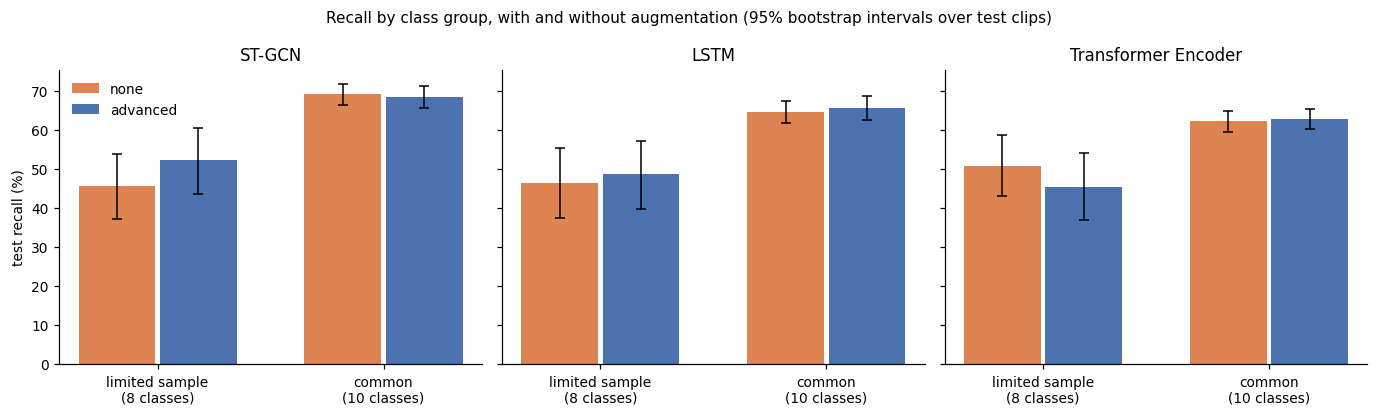

In [7]:
fig, axes = plt.subplots(1, len(models_present), figsize=(4.2 * len(models_present), 3.8), sharey=True, squeeze=False)
for ax, m in zip(axes[0], models_present):
    for j, g in enumerate(GROUPS):
        r = aug[m][g]
        for k, (key, colour, name) in enumerate([("b", "#dd8452", "none"), ("a", "#4c72b0", "advanced")]):
            ci_ = r[key + "_ci"]
            ax.bar(j + (k - 0.5) * 0.36, 100 * r[key], width=0.34, color=colour, label=name if j == 0 else None)
            ax.errorbar(j + (k - 0.5) * 0.36, 100 * r[key], yerr=[[100 * (r[key] - ci_[0])], [100 * (ci_[1] - r[key])]],
                        color="black", capsize=3, lw=1)
    ax.set_xticks(range(len(GROUPS)), [f"{g}\n({len(GROUPS[g])} classes)" for g in GROUPS])
    ax.set_title(MODEL_LABEL[m])
axes[0, 0].set_ylabel("test recall (%)")
axes[0, 0].legend(frameon=False)
fig.suptitle("Recall by class group, with and without augmentation (95% bootstrap intervals over test clips)", fontsize=10)
fig.tight_layout()
publish(fig, "recall by class group")

## 2. Does any effect scale with class size?

Per class change in test recall (advanced minus none) against training set size. If augmentation helped
mainly where data is scarce, the change would be positive on the left and shrink to zero on the right.

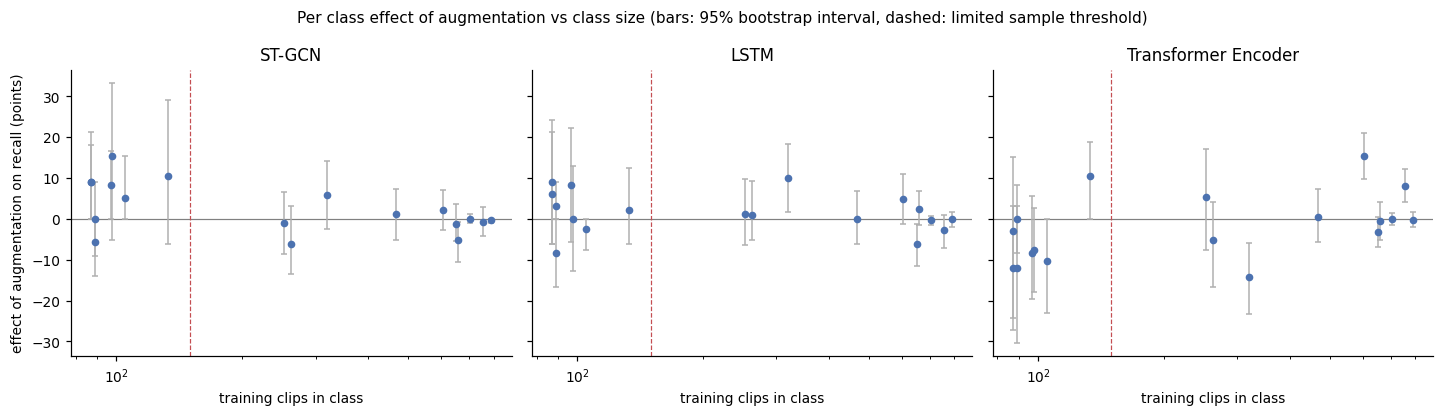

,model,Spearman rho (train size vs effect),p
0,ST-GCN,-0.45,0.06
1,LSTM,-0.37,0.13
2,Transformer Encoder,0.45,0.06


In [8]:
fig, axes = plt.subplots(1, len(models_present), figsize=(4.4 * len(models_present), 3.8), sharey=True, squeeze=False)
rho_rows = []
for ax, m in zip(axes[0], models_present):
    pc = aug[m]["per_class"]
    x = train_counts.reindex(pc.index).to_numpy()
    ax.axhline(0, color="grey", lw=0.8)
    ax.errorbar(x, 100 * pc["delta"], yerr=[100 * (pc["delta"] - pc["lo"]), 100 * (pc["hi"] - pc["delta"])],
                fmt="o", ms=4, color="#4c72b0", ecolor="#b0b0b0", capsize=2, lw=1)
    ax.axvline(RARE_THRESHOLD, color="#c44e52", ls="--", lw=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("training clips in class")
    ax.set_title(MODEL_LABEL[m])
    rho, p = spearmanr(x, pc["delta"])
    rho_rows.append({"model": MODEL_LABEL[m], "Spearman rho (train size vs effect)": round(float(rho), 2), "p": round(float(p), 2)})
axes[0, 0].set_ylabel("effect of augmentation on recall (points)")
fig.suptitle("Per class effect of augmentation vs class size (bars: 95% bootstrap interval, dashed: limited sample threshold)", fontsize=10)
fig.tight_layout()
publish(fig, "per class augmentation effect vs class size")
rho_table = pd.DataFrame(rho_rows)
logger.report_table("rank correlation", "analysis", iteration=0, table_plot=rho_table)
rho_table

## 3. Class balancing, and augmentation on top of it (ST-GCN, validation set, notebook 12)

Only validation predictions exist for the natural frequency baseline, and the validation set has fewer
clips in the small classes, so intervals here are wider than on test.

In [9]:
fam = {}
for path in glob.glob(f"{OUTPUTS}/experiments/augmentation_families/**/*_predictions.csv", recursive=True):
    run = os.path.basename(path).replace("_predictions.csv", "")
    m = FAM_RE.match(run)
    if m:
        fam.setdefault(m.group(1), {})[int(m.group(2))] = path

fam_data = {}
for cfg, seeds in fam.items():
    labels, correct = None, []
    for s, path in sorted(seeds.items()):
        fp, lab, cor = load_predictions(path, "val")
        labels = lab if labels is None else labels
        correct.append(cor)
    fam_data[cfg] = {"labels": labels, "correct": np.stack(correct)}
print("configurations found:", sorted(fam_data))

bal_rows, bal_res = [], {}
if {"none_natural", "none_balanced", "advanced"} <= set(fam_data):
    lab = fam_data["none_natural"]["labels"]
    for name, a, b in [("class balancing (balanced - natural)", "none_balanced", "none_natural"),
                       ("augmentation on top of balancing (advanced - none, balanced)", "advanced", "none_balanced")]:
        bal_res[name] = compare(lab, fam_data[a]["correct"], fam_data[b]["correct"])
        for g in list(GROUPS) + ["mca"]:
            r = bal_res[name][g]
            bal_rows.append({"effect": name, "group": g if g != "mca" else "all classes (MCA)",
                             "effect (points)": f"{100 * r['delta']:+.1f}",
                             "95% CI": f"[{100 * r['delta_ci'][0]:+.1f}, {100 * r['delta_ci'][1]:+.1f}]"})
    bal_table = pd.DataFrame(bal_rows)
    logger.report_table("balancing and augmentation effects (ST-GCN, validation)", "analysis", iteration=0, table_plot=bal_table)
else:
    bal_table = pd.DataFrame()
    print("notebook 12 predictions not found, skipping this section")
bal_table

configurations found: ['advanced', 'basic', 'basic_plus_advanced', 'none_balanced', 'none_natural']


,effect,group,effect (points),95% CI
0,class balancing (balanced - natural),limited sample,+6.4,"[+2.7, +10.4]"
1,class balancing (balanced - natural),common,-1.2,"[-3.5, +0.9]"
2,class balancing (balanced - natural),all classes (MCA),+2.2,"[+0.1, +4.3]"
3,augmentation on top of balancing (advanced - n...,limited sample,-2.6,"[-5.7, +0.6]"
4,augmentation on top of balancing (advanced - n...,common,+0.3,"[-1.7, +2.4]"
5,augmentation on top of balancing (advanced - n...,all classes (MCA),-1.0,"[-2.8, +0.9]"


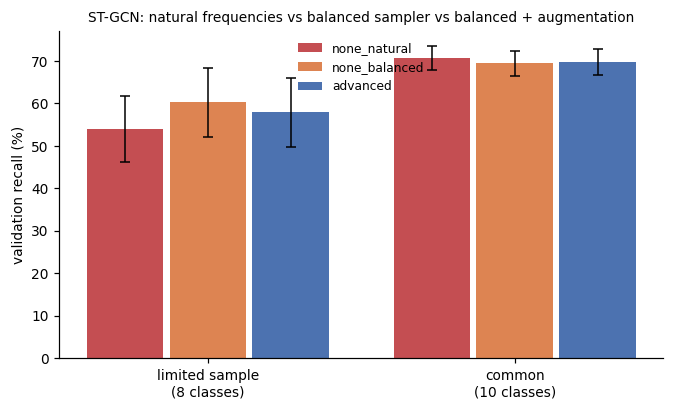

In [10]:
if bal_res:
    cfgs = [c for c in ["none_natural", "none_balanced", "advanced"] if c in fam_data]
    colours = {"none_natural": "#c44e52", "none_balanced": "#dd8452", "advanced": "#4c72b0"}
    lab = fam_data[cfgs[0]]["labels"]
    samples = boot_samples(lab, N_BOOT)
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    for k, c in enumerate(cfgs):
        cm = fam_data[c]["correct"].mean(axis=0)
        rec = class_recalls(cm, lab)
        boot = boot_recalls(cm, samples)
        for j, (g, ids) in enumerate(GROUPS.items()):
            lo, hi = ci(boot[:, ids].mean(axis=1))
            x = j + (k - 1) * 0.27
            ax.bar(x, 100 * group_recall(rec, ids), width=0.25, color=colours[c], label=c if j == 0 else None)
            ax.errorbar(x, 100 * group_recall(rec, ids), yerr=[[100 * (group_recall(rec, ids) - lo)], [100 * (hi - group_recall(rec, ids))]],
                        color="black", capsize=3, lw=1)
    ax.set_xticks(range(len(GROUPS)), [f"{g}\n({len(GROUPS[g])} classes)" for g in GROUPS])
    ax.set_ylabel("validation recall (%)")
    ax.legend(frameon=False, fontsize=8)
    ax.set_title("ST-GCN: natural frequencies vs balanced sampler vs balanced + augmentation", fontsize=9)
    fig.tight_layout()
    publish(fig, "balancing effect by class group")

## 4. What the test set can resolve, and sensitivity to the group threshold

In [11]:
rows = []
for m in models_present:
    r = aug[m]["limited sample"]
    half = 100 * (r["delta_ci"][1] - r["delta_ci"][0]) / 2
    rows.append({"model": MODEL_LABEL[m], "limited sample test clips": n_rare_test,
                 "interval half width (points)": round(half, 1),
                 "reading": ("effect not distinguishable from zero" if r["delta_ci"][0] <= 0 <= r["delta_ci"][1]
                             else ("augmentation helps" if r["delta"] > 0 else "augmentation hurts"))})
resolve = pd.DataFrame(rows)
logger.report_table("what the test set can resolve", "analysis", iteration=0, table_plot=resolve)
resolve

,model,limited sample test clips,interval half width (points),reading
0,ST-GCN,99,4.3,augmentation helps
1,LSTM,99,3.9,effect not distinguishable from zero
2,Transformer Encoder,99,4.8,augmentation hurts


In [12]:
sens = []
for thr in [100, 150, 270, 400]:
    ids = [cid[c] for c in class_names if train_counts[c] < thr]
    for m in models_present:
        a, b = test_data[(m, "advanced")], test_data[(m, "none")]
        ra = class_recalls(a["correct"].mean(axis=0), a["labels"])
        rb = class_recalls(b["correct"].mean(axis=0), b["labels"])
        sens.append({"threshold (train clips)": thr, "classes in group": len(ids), "model": MODEL_LABEL[m],
                     "effect (points)": round(100 * (ra[ids].mean() - rb[ids].mean()), 1)})
sens_table = pd.DataFrame(sens).pivot_table(index=["threshold (train clips)", "classes in group"], columns="model", values="effect (points)")
logger.report_table("sensitivity to the group threshold", "analysis", iteration=0, table_plot=sens_table.reset_index())
for m in models_present:
    logger.report_single_value(f"{m}_aug_effect_limited_sample_points", 100 * aug[m]["limited sample"]["delta"])
task.close()
sens_table

,model,LSTM,ST-GCN,Transformer Encoder
threshold (train clips),classes in group,,,
100,6,3.0,6.1,-7.2
150,8,2.2,6.5,-5.4
270,10,2.0,4.5,-4.3
400,11,2.7,4.6,-5.2


## Reading the result

- The intervals show the size of effect the held out test set could detect for the limited sample group.
  An effect smaller than the half width in section 4 cannot be confirmed or ruled out with these clips, in
  either direction. That is a statement about the test set size, not about the models.
- If the per class effects (section 2) show no relationship with class size, augmentation is not acting
  as a small class remedy in this pipeline, whatever its overall effect.
- The balancing result (section 3) is the cleaner contrast: the balanced sampler is what moves recall in the
  limited sample classes, at a small cost to the common classes.
- To resolve smaller effects, the number of limited sample test clips has to grow. The practical way is
  k fold cross validation over the full dataset, which pools every clip of the limited sample classes into the
  evaluation (about 980 clips instead of about 100).